# Paskong Pinoy: A Visual Celebration of Christmas in the Philippines

**Module 1 ? Consistent Media Generation on Serverless GPUs**

This experiment generates ten Filipino Christmas illustrations using the official Sana 1600M model through a Nebius Serverless Endpoint.

The notebook uses the official course helper code. It does not modify the original course notebook.

**Measurement policy:** Endpoint startup, model API readiness, individual generation latency, and total run duration are recorded separately wherever measurable. Internal model-loading time is not inferred from readiness time.


## 1. Imports and project discovery

Find the course repository, load the prompt file, and import the official image-generation helpers.


In [1]:
import hashlib
import json
import re
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

# Locate the repository from the current notebook working directory.
current = Path.cwd().resolve()
REPO_ROOT = next(
    (
        parent for parent in (current, *current.parents)
        if (parent / "01-consistent-media-generation-on-serverless-gpus" / "code" / "image.py").exists()
    ),
    None,
)

if REPO_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the course repository. Open JupyterLab from the repository root."
    )

PROJECT_DIR = REPO_ROOT / "paskong-pinoy-module1"
CODE_DIR = REPO_ROOT / "01-consistent-media-generation-on-serverless-gpus" / "code"
PROMPTS_FILE = PROJECT_DIR / "prompts.json"

if not PROMPTS_FILE.exists():
    raise FileNotFoundError(f"Prompt file not found: {PROMPTS_FILE}")

sys.path.insert(0, str(CODE_DIR))

import common
from image import ImageGenerator
from models import SANA

with PROMPTS_FILE.open("r", encoding="utf-8-sig") as f:
    prompt_data = json.load(f)

assert len(prompt_data["images"]) == 10, "Expected exactly ten image prompts."

print("Repository:", REPO_ROOT)
print("Project:", PROJECT_DIR)
print("Model:", SANA.model)
print("Prompt count:", len(prompt_data["images"]))


Repository: C:\Users\kambar\OneDrive\Documents\production-ai-agents-for-media-generation
Project: C:\Users\kambar\OneDrive\Documents\production-ai-agents-for-media-generation\paskong-pinoy-module1
Model: Efficient-Large-Model/Sana_1600M_1024px_diffusers
Prompt count: 10


## 2. Experiment configuration

We use a 1024 ? 1024 output, 20 inference steps, guidance scale 4.5, and ten distinct seeds.

The 1024 ? 1024 choice is an experiment setting, not a claim that it will be faster or cheaper than 512 ? 512.


In [2]:
IMAGE_SIZE = "1024x1024"
INFERENCE_STEPS = 20
GUIDANCE_SCALE = 4.5
FIRST_SEED = 7
NEGATIVE_PROMPT = SANA.negative_prompt
READINESS_TIMEOUT_S = 600
REQUEST_TIMEOUT_S = 300

RUN_STARTED_UTC = datetime.now(timezone.utc)
RUN_ID = RUN_STARTED_UTC.strftime("paskong-pinoy-%Y%m%dT%H%M%SZ")
RUN_DIR = PROJECT_DIR / "runs" / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

shared_style = prompt_data["shared_style"]

config = {
    "project": prompt_data["project"],
    "model": SANA.model,
    "model_revision": SANA.model_revision,
    "gpu": SANA.gpu,
    "image_size": IMAGE_SIZE,
    "num_inference_steps": INFERENCE_STEPS,
    "guidance_scale": GUIDANCE_SCALE,
    "first_seed": FIRST_SEED,
    "image_count": len(prompt_data["images"]),
    "output_format": "PNG",
}

print(json.dumps(config, indent=2))
print("Run directory:", RUN_DIR)


{
  "project": "Paskong Pinoy: A Visual Celebration of Christmas in the Philippines",
  "model": "Efficient-Large-Model/Sana_1600M_1024px_diffusers",
  "model_revision": "ac0da2ff55fbe434795be0dce883042e4d49e2fc",
  "gpu": "L40S",
  "image_size": "1024x1024",
  "num_inference_steps": 20,
  "guidance_scale": 4.5,
  "first_seed": 7,
  "image_count": 10,
  "output_format": "PNG"
}
Run directory: C:\Users\kambar\OneDrive\Documents\production-ai-agents-for-media-generation\paskong-pinoy-module1\runs\paskong-pinoy-20261126T043156Z


## 3. Endpoint connection and readiness

Create the endpoint in Nebius first. Record the time you start it and the time it reaches `RUNNING` in the console.

The course helper securely prompts for missing endpoint credentials and saves them in the course `code/.env` file, which is Git-ignored.

Do not print or share the endpoint URL or token.


In [3]:
# The course helper reads the private course code/.env file.
BASE_URL, TOKEN = common.setup_endpoint()

print("Endpoint credentials loaded. Values are intentionally not displayed.")

startup_s_input = input(
    "Enter endpoint startup duration in seconds (from console start to RUNNING): "
).strip()

startup_s = float(startup_s_input) if startup_s_input else None
if startup_s is not None and startup_s < 0:
    raise ValueError("Startup duration cannot be negative.")

readiness_start = time.perf_counter()
ready_response = common.wait_ready(
    BASE_URL,
    TOKEN,
    deadline_s=READINESS_TIMEOUT_S,
)
ready_wait_s = time.perf_counter() - readiness_start

print(f"Model API readiness wait: {ready_wait_s:.2f} seconds")
print("The endpoint returned a non-empty model list.")


Endpoint configured (***ZC7S)
Endpoint credentials loaded. Values are intentionally not displayed.


Enter endpoint startup duration in seconds (from console start to RUNNING):  300


Model API readiness wait: 0.95 seconds
The endpoint returned a non-empty model list.


## 4. Generate the ten images

All ten requests run sequentially through one endpoint connection. We deliberately do not use `cached_image()`: each image must be a real generation request for this benchmark.

The shared style is appended to every scene prompt. A unique seed is assigned to each image.


In [12]:
generator = ImageGenerator(
    endpoint=BASE_URL,
    token=TOKEN,
    model=SANA.model,
)

generation_records = []
generation_errors = []

generation_run_start = time.perf_counter()

for item in prompt_data["images"]:
    image_id = int(item["id"])
    seed = FIRST_SEED + image_id - 1

    slug = re.sub(r"[^a-z0-9]+", "-", item["title"].lower()).strip("-")
    output_path = RUN_DIR / f"{image_id:02d}-{slug}.png"
    full_prompt = f"{item['prompt']} {shared_style}"

    print(f"\n[{image_id}/10] {item['title']}")

    request_start = time.perf_counter()

    try:
        saved_path = generator.generate_image(
            full_prompt,
            out=output_path,
            seed=seed,
            size=IMAGE_SIZE,
            num_inference_steps=INFERENCE_STEPS,
            guidance_scale=GUIDANCE_SCALE,
            negative_prompt=NEGATIVE_PROMPT,
            timeout=REQUEST_TIMEOUT_S,
        )

        wall_request_s = time.perf_counter() - request_start
        api_latency_s = generator.last_s

        file_bytes = saved_path.read_bytes()
        if not file_bytes.startswith(b"\x89PNG\r\n\x1a\n"):
            raise ValueError(f"Invalid PNG signature: {saved_path}")

        record = {
            "id": image_id,
            "title": item["title"],
            "seed": seed,
            "file": saved_path.name,
            "bytes": len(file_bytes),
            "sha256": hashlib.sha256(file_bytes).hexdigest(),
            "api_latency_s": api_latency_s,
            "wall_request_s": wall_request_s,
            "status": "success",
        }
        generation_records.append(record)

        print(f"Saved: {saved_path.name}")
        print(f"API request latency: {api_latency_s:.2f} s")
        print(f"Request wall time: {wall_request_s:.2f} s")

    except Exception as exc:
        wall_request_s = time.perf_counter() - request_start
        error_record = {
            "id": image_id,
            "title": item["title"],
            "seed": seed,
            "wall_request_s": wall_request_s,
            "status": "failed",
            "error": repr(exc),
        }
        generation_errors.append(error_record)
        print(f"FAILED: {type(exc).__name__}: {exc}")

total_generation_wall_s = time.perf_counter() - generation_run_start

print("\nGeneration loop finished.")
print("Successful images:", len(generation_records))
print("Failed images:", len(generation_errors))
print(f"Total generation-loop wall time: {total_generation_wall_s:.2f} s")


print("Generator available:", "generator" in globals())
print("Run directory available:", "RUN_DIR" in globals())
print("Endpoint configuration available:", "BASE_URL" in globals() and "TOKEN" in globals())
print("Image size:", IMAGE_SIZE if "IMAGE_SIZE" in globals() else "Not loaded")
print("Inference steps:", INFERENCE_STEPS if "INFERENCE_STEPS" in globals() else "Not loaded")




[1/10] The Filipino Parol
FAILED: RuntimeError: HTTP 404 from /v1/images/generations: {"type":"about:blank","title":"Not Found","status":404,"detail":"No tunnel has this address.","reason":"unknown_tunnel","scope":"pod"}


[2/10] Paskong Barangay
FAILED: RuntimeError: HTTP 404 from /v1/images/generations: {"type":"about:blank","title":"Not Found","status":404,"detail":"No tunnel has this address.","reason":"unknown_tunnel","scope":"pod"}


[3/10] Simbang Gabi
FAILED: RuntimeError: HTTP 404 from /v1/images/generations: {"type":"about:blank","title":"Not Found","status":404,"detail":"No tunnel has this address.","reason":"unknown_tunnel","scope":"pod"}


[4/10] Noche Buena
FAILED: RuntimeError: HTTP 404 from /v1/images/generations: {"type":"about:blank","title":"Not Found","status":404,"detail":"No tunnel has this address.","reason":"unknown_tunnel","scope":"pod"}


[5/10] Filipino Christmas Delicacies
FAILED: RuntimeError: HTTP 404 from /v1/images/generations: {"type":"about:blank","ti

In [13]:
import json
import shutil
import hashlib
import time

# Reload the updated prompt from prompts.json
PROJECT_DIR = RUN_DIR.parents[1]

with open(PROJECT_DIR / "prompts.json", encoding="utf-8-sig") as f:
    updated_data = json.load(f)

item = next(
    image for image in updated_data["images"]
    if int(image["id"]) == 1
)

# Preserve the original seed and generation settings
seed = FIRST_SEED
full_prompt = f"{item['prompt']} {updated_data['shared_style']}"

# Generate to a temporary candidate file first
candidate_path = RUN_DIR / "01-the-filipino-parol-replacement.png"
original_path = RUN_DIR / "01-the-filipino-parol.png"
backup_path = RUN_DIR / "01-the-filipino-parol-original-backup.png"

print("Generating:", item["title"])
print("Seed:", seed)
print("Image size:", IMAGE_SIZE)

start = time.perf_counter()

saved_path = generator.generate_image(
    full_prompt,
    out=candidate_path,
    seed=seed,
    size=IMAGE_SIZE,
    num_inference_steps=INFERENCE_STEPS,
    guidance_scale=GUIDANCE_SCALE,
    negative_prompt=NEGATIVE_PROMPT,
    timeout=REQUEST_TIMEOUT_S,
)

elapsed = time.perf_counter() - start

# Validate the new image before replacing the original
image_bytes = saved_path.read_bytes()

if not image_bytes.startswith(b"\x89PNG\r\n\x1a\n"):
    raise ValueError("The generated file is not a valid PNG.")

if not original_path.is_file():
    raise FileNotFoundError(f"Original image missing: {original_path}")

# Preserve the original image as a backup
if not backup_path.exists():
    shutil.copy2(original_path, backup_path)

# Replace only image 01
shutil.copy2(saved_path, original_path)

print("\nReplacement successful!")
print("Updated image:", original_path.name)
print("Original backup:", backup_path.name)
print("File size:", len(image_bytes), "bytes")
print(f"Generation time: {elapsed:.2f} seconds")
print("SHA256:", hashlib.sha256(image_bytes).hexdigest())

Generating: The Filipino Parol
Seed: 7
Image size: 1024x1024
Generated in 11.9 s

Replacement successful!
Updated image: 01-the-filipino-parol.png
Original backup: 01-the-filipino-parol-original-backup.png
File size: 1700761 bytes
Generation time: 11.93 seconds
SHA256: 1b06c3f0dadf93c9b7f9f925d28c3b9ff9289f78f56e85f889ed426bafbd5b13


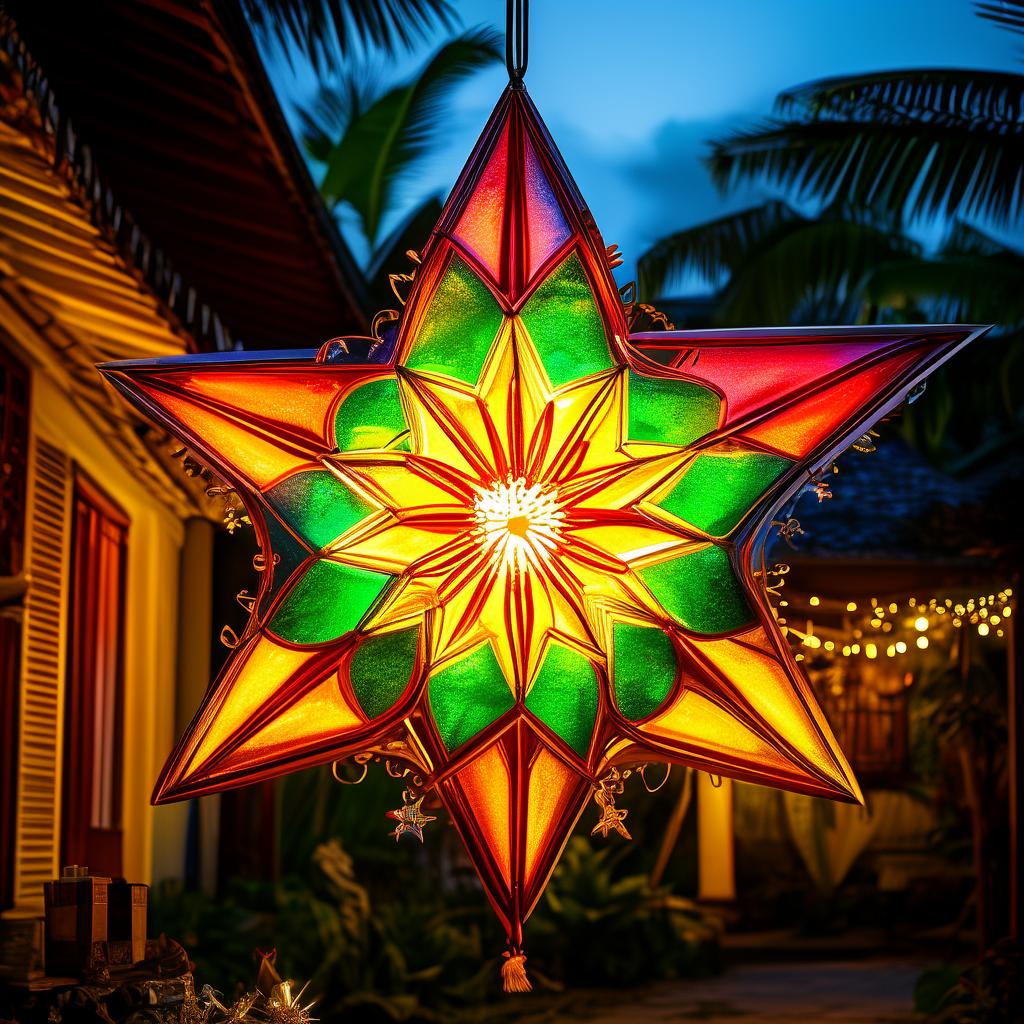

In [15]:
from IPython.display import display, Image

replacement_path = RUN_DIR / "01-the-filipino-parol.png"
display(Image(filename=str(replacement_path), width=700))

In [16]:
from pathlib import Path

for i in range(1, 11):
    matches = list(RUN_DIR.glob(f"{i:02d}-*.png"))
    for path in matches:
        print(f"{i:02d}: {path.name} | Exists: {path.is_file()} | Size: {path.stat().st_size:,} bytes")

01: 01-the-filipino-parol-original-backup.png | Exists: True | Size: 1,325,200 bytes
01: 01-the-filipino-parol-replacement.png | Exists: True | Size: 1,700,761 bytes
01: 01-the-filipino-parol.png | Exists: True | Size: 1,700,761 bytes
02: 02-paskong-barangay.png | Exists: True | Size: 1,865,219 bytes
03: 03-simbang-gabi.png | Exists: True | Size: 1,819,855 bytes
04: 04-noche-buena.png | Exists: True | Size: 1,507,913 bytes
05: 05-filipino-christmas-delicacies.png | Exists: True | Size: 1,402,591 bytes
06: 06-giant-lantern-festival.png | Exists: True | Size: 1,862,392 bytes
07: 07-family-christmas-preparations.png | Exists: True | Size: 1,556,166 bytes
08: 08-christmas-caroling.png | Exists: True | Size: 1,395,298 bytes
09: 09-the-joy-of-giving.png | Exists: True | Size: 1,453,439 bytes
10: 10-a-filipino-christmas-night.png | Exists: True | Size: 1,973,780 bytes


## 5. Review generated files

Check that each successful image exists and is a valid PNG. Open the files in the JupyterLab file browser to review visual quality and cultural relevance.


In [14]:
for record in generation_records:
    path = RUN_DIR / record["file"]
    print(
        f'{record["id"]:02d}. {record["title"]}: '
        f'{path.exists()} | {record["bytes"]:,} bytes | '
        f'{record["api_latency_s"]:.2f} s'
    )

print("\nSuccessful:", len(generation_records))
print("Failed:", len(generation_errors))



Successful: 0
Failed: 10


## 6. Save experiment metrics

`ready_wait_s` measures the time from beginning the `/v1/models` readiness check until the model API responds.

`load_s` remains null unless a separate, trustworthy model-loading measurement is available. Do not treat readiness wait as an independently measured internal model-load duration.

The actual provider billing record should be checked separately in Nebius Billing.


In [6]:
run_finished_utc = datetime.now(timezone.utc)

metrics_data = {
    "schema_version": 1,
    "project": prompt_data["project"],
    "run_id": RUN_ID,
    "started_utc": RUN_STARTED_UTC.isoformat(),
    "finished_utc": run_finished_utc.isoformat(),
    "mode": "nebius_serverless_endpoint",
    "startup_s": startup_s,
    "ready_wait_s": ready_wait_s,
    "load_s": None,
    "latency_s": [r["api_latency_s"] for r in generation_records],
    "total_generation_wall_s": total_generation_wall_s,
    "billable_s": None,
    "billing_basis": "Check actual provider usage; endpoint billing interval must be verified.",
    "config": config,
    "assets": generation_records,
    "errors": generation_errors,
    "status": (
        "completed"
        if len(generation_records) == 10 and not generation_errors
        else "incomplete"
    ),
}

metrics_path = RUN_DIR / "metrics.json"
with metrics_path.open("w", encoding="utf-8") as f:
    json.dump(metrics_data, f, indent=2)

print("Metrics saved:", metrics_path)
print("Run status:", metrics_data["status"])


Metrics saved: C:\Users\kambar\OneDrive\Documents\production-ai-agents-for-media-generation\paskong-pinoy-module1\runs\paskong-pinoy-20261126T043156Z\metrics.json
Run status: completed


## 7. Cost analysis

Enter the actual GPU hourly rate shown for your endpoint configuration. Do not use example prices from course notebooks or old screenshots.

The helper calculates marginal and fixed costs from measured durations. Since internal model-load duration and exact provider billable time may not be independently available, interpret the estimate accordingly.


In [8]:

if len(generation_records) != 10 or generation_errors:
    print("Cost analysis is deferred until all ten generations succeed.")
else:
    rate_input = input("Enter actual GPU price in USD per hour: ").strip()
    if not rate_input:
        print("No rate entered. Cost calculation skipped.")
    else:
        gpu_rate_usd_per_hour = float(rate_input)
        if gpu_rate_usd_per_hour <= 0:
            raise ValueError("GPU hourly rate must be positive.")

        # Service-reported model initialization duration from Nebius logs.
        model_load_s = 48.8

        # Save the measured model initialization duration in metrics.
        metrics_data["load_s"] = model_load_s

        cost_result = common.calculate_cost(
            startup_s=startup_s or 0.0,
            ready_s=model_load_s,
            latency_s=[r["api_latency_s"] for r in generation_records],
            price_per_hour=gpu_rate_usd_per_hour,
            counts=(1, 10, 100, 1000),
        )

        metrics_data["cost_analysis"] = {
            "gpu_rate_usd_per_hour": gpu_rate_usd_per_hour,
            "assumption": (
                "Fixed cost uses approximately 300 seconds of endpoint startup "
                "plus 48.8 seconds of service-reported model initialization "
                "and readiness. API polling wait is recorded separately."
            ),
            "calculation": cost_result,
        }

        with metrics_path.open("w", encoding="utf-8") as f:
            json.dump(metrics_data, f, indent=2)

        print(json.dumps(cost_result, indent=2))


Enter actual GPU price in USD per hour:  0.65


{
  "marginal_compute_usd": 0.0014852039402769353,
  "fixed_run_usd": 0.06297777777777779,
  "projected_compute_usd_per_asset": {
    "1": 0.06446298171805472,
    "10": 0.007782981718054714,
    "100": 0.002114981718054713,
    "1000": 0.0015481817180547132
  },
  "breakeven_assets": null
}


## 8. Cleanup reminder

After collecting the experiment results, stop the Nebius endpoint in the console to prevent further compute charges. Verify actual usage in Billing.

Do not delete the run evidence until it has been reviewed and safely backed up.
